# Ex13 (10/12) 130page 우편번호(손글씨 숫자) - ML + DL

130page 예제(KNN)에 Decision Tree, Random Forest를 더하고, **딥러닝(Multi-class)** 을 추가합니다.
숫자는 0~9 **10개 클래스**이므로 정답을 **원-핫 인코딩**하고 출력층을 **Dense(10, softmax)** 로 만듭니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split

tf.random.set_seed(42)
np.random.seed(42)

I0000 00:00:1792959525.333167    9379 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792959526.915733    9379 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


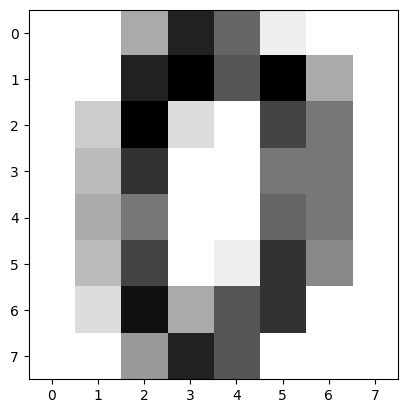

이미지 개수: 1797  / 이미지 크기: (8, 8)


In [2]:
digits = datasets.load_digits()
plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

print("이미지 개수:", len(digits.images), " / 이미지 크기:", digits.images[0].shape)

In [3]:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))   # 8x8 이미지 → 64개 값으로 펼치기

X_train, X_test, y_train, y_test = train_test_split(data, digits.target, test_size=0.2, random_state=42)

X_train.shape, X_test.shape

((1437, 64), (360, 64))

# Machine Learning

In [4]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=6)

knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("KNN accuracy:", metrics.accuracy_score(y_test, y_pred))

KNN accuracy: 0.9888888888888889


In [5]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

print("Decision Tree accuracy:", metrics.accuracy_score(y_test, y_pred))

Decision Tree accuracy: 0.8416666666666667


In [6]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("Random Forest accuracy:", metrics.accuracy_score(y_test, y_pred))

Random Forest accuracy: 0.9722222222222222


# DL_multi-class, single-label

1. **정규화**: 픽셀 값은 0~16이므로 16으로 나눠서 0~1로 맞춥니다.
2. **원-핫 인코딩**: 정답 숫자를 길이 10짜리 벡터로 바꿉니다. 예: 3 → [0,0,0,1,0,0,0,0,0,0]
3. **모델**: 입력 64개 → Dense(64, relu) → Dense(32, relu) → **Dense(10, softmax)**
4. **손실함수**: categorical_crossentropy

In [7]:
X_train_dl = X_train / 16.0
X_test_dl = X_test / 16.0

y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=10)

print("원래 정답:", y_train[0])
print("원-핫    :", y_train_oh[0])

원래 정답: 6
원-핫    : [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


In [8]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(64,)))
model.add(tf.keras.layers.Dense(64, activation="relu"))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(X_train_dl, y_train_oh, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

print("마지막 학습 정확도 :", round(history.history['accuracy'][-1], 4))
print("마지막 검증 정확도 :", round(history.history['val_accuracy'][-1], 4))

마지막 학습 정확도 : 0.9974
마지막 검증 정확도 : 0.9444


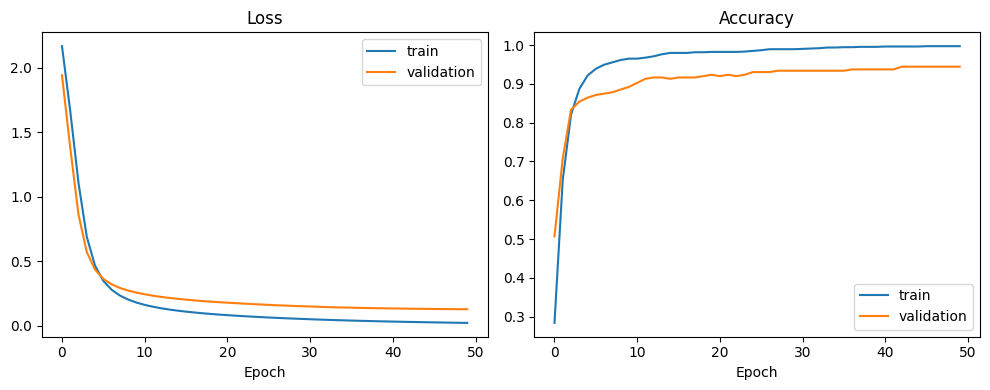

In [10]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout()
plt.show()

In [11]:
y_prob = model.predict(X_test_dl, verbose=0)
y_pred = np.argmax(y_prob, axis=1)      # 10개 확률 중 가장 큰 위치 = 예측 숫자

print("DL accuracy =", metrics.accuracy_score(y_test, y_pred))
print("\nConfusion Matrix")
print(metrics.confusion_matrix(y_test, y_pred))
print("\nClassification Report")
print(metrics.classification_report(y_test, y_pred))

DL accuracy = 0.9555555555555556

Confusion Matrix
[[32  0  0  0  1  0  0  0  0  0]
 [ 0 27  0  0  0  0  0  0  0  1]
 [ 0  1 32  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  1  0  0 44  1  0  0  1]
 [ 1  0  0  0  0  0 34  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  2  0  0  0  1  0  0 27  0]
 [ 0  0  0  2  0  0  0  0  2 36]]

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        33
           1       0.90      0.96      0.93        28
           2       0.97      0.97      0.97        33
           3       0.94      0.97      0.96        34
           4       0.98      1.00      0.99        46
           5       0.96      0.94      0.95        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.93      0.90      0.92        30
           9       0.92      0.90      0.91        40


## 같은 이미지로 4개 모델 비교

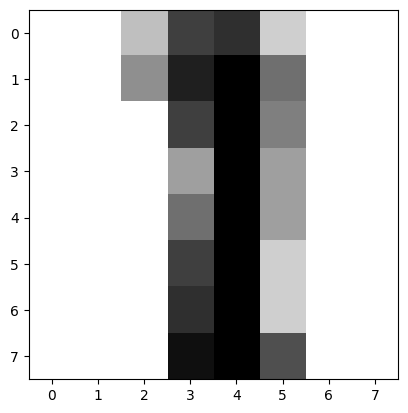

정답         : 1
KNN          : 1
DecisionTree : 2
RandomForest : 1


DL           : 1


In [12]:
i = 10
plt.imshow(X_test[i].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

print("정답         :", y_test[i])
print("KNN          :", knn.predict([X_test[i]])[0])
print("DecisionTree :", dt.predict([X_test[i]])[0])
print("RandomForest :", rf.predict([X_test[i]])[0])
print("DL           :", np.argmax(model.predict(X_test_dl[i:i+1], verbose=0)))

# 결과 정리

- KNN, Random Forest, DL이 모두 높은 정확도를 보였고, Decision Tree가 가장 낮았습니다. 손글씨는 픽셀 하나하나로 규칙을 나누기 어렵기 때문입니다.
- DL에서는 정답을 **원-핫 인코딩**하고, 출력층 노드 수를 **클래스 수(10)** 와 같게 해야 softmax + categorical_crossentropy가 제대로 동작합니다.
- 예측할 때는 softmax의 10개 확률 중 **argmax**로 가장 큰 값을 예측 숫자로 고릅니다.